<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and fixture provenance](README.md)

# 01 · Did the DNS inventory keep every scope and every record?

An inventory can lose information in two ways: an inner join can discard an unresolved zone, and grouping only by DNS name can merge distinct record IDs. We will retain an explicit list of expected scopes, fetch all DNS pages for resolved zones, and compare record counts with name counts before constructing a small review queue.

**Every account, zone and DNS record here is synthetic.** The real Cloudflare worker calls the repository's shipped fake HTTP API on loopback, with a dummy credential. No Cloudflare account is contacted, no DNS lookup is performed, and no configuration is changed. The fixture tests SQL mapping, pagination and join behavior; it does not model authorization or real DNS policy.

## Choose a workload-review threshold

`REVIEW_MIN_RECORDS` is a count threshold for prioritizing this small inventory: a resolved zone enters the count-based queue when it has at least that many distinct record IDs. It is a teaching parameter, not a Cloudflare limit or a security rule. Unresolved scopes stay in a separate follow-up category at every threshold.

Change only **4 → 6 records** in the experiment. Predict a smaller count-based queue with unchanged source data and unchanged unresolved scopes. Accepted values are integers 1–10. Restart the kernel and Run All after editing.

In [1]:
REVIEW_MIN_RECORDS = 4  # Integer 1–10 DNS records; experiment: 6

In [2]:
import hashlib
import os
import threading
from datetime import UTC, datetime
from http.server import ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urlparse

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from mock_cloudflare import _Handler

scope_status: pd.DataFrame
records: pd.DataFrame
counts: pd.DataFrame
identity_counts: pd.DataFrame

assert type(REVIEW_MIN_RECORDS) is int and 1 <= REVIEW_MIN_RECORDS <= 10
requests = []


class ObservedHandler(_Handler):
    def do_GET(self):
        requests.append(self.path)
        super().do_GET()

    def do_POST(self):
        self.send_error(405, "This inventory fixture permits GET only")


server = ThreadingHTTPServer(("127.0.0.1", 0), ObservedHandler)
server_thread = threading.Thread(target=server.serve_forever, daemon=True)
server_thread.start()
os.environ["CLOUDFLARE_API_BASE"] = f"http://127.0.0.1:{server.server_port}/client/v4"
for name in ["CLOUDFLARE_API_TOKEN", "VGI_CLOUDFLARE_TOKEN_FILE", "VGI_BEARER_TOKENS"]:
    os.environ.pop(name, None)
os.environ["PLOOMBER_STATS_ENABLED"] = "false"
fixture_hash = hashlib.sha256(Path("mock_cloudflare.py").read_bytes()).hexdigest()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        "Source: real Cloudflare worker + shipped synthetic loopback API · current run · no live account data",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.05, 1, 0.96))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-cloudflare/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-cloudflare/notebooks/pyproject.toml.

## Attach the immutable worker with an explicit compatibility override

The literal uvx command fetches a remote Git commit; no local worker checkout is used. The companion `worker-overrides.txt` selects **vgi-python 0.51.1**, whose protocol matches Haybarn 2.0.0rc11. The worker's declared 0.50 runtime speaks protocol 3.2 and cannot attach to this engine's 3.3. The README records this notebook-only override and its validation; worker source and root dependencies remain unchanged.

The setup starts the synthetic API at an OS-assigned loopback port and passes that base URL to the worker. The following secret is deliberately a noncredential, accepted only by our local fixture. It must never be replaced with a real token in saved SQL.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'cloudflare' AS cf (
    TYPE vgi,
    LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-cloudflare@cd61c287abe0566facfc40f7b7a0844d59f95b85 --overrides worker-overrides.txt --with haybarn==1.5.5rc1 vgi-cloudflare'
);
CREATE SECRET fixture_cf (TYPE cloudflare,api_token 'fixture-only-not-a-token');

,Success


## Keep the intended scopes when lookups return no row

The input list deliberately contains three valid fixture IDs, one unknown ID and one missing ID. `LEFT JOIN LATERAL` preserves each input row even when the lookup produces no result. An unresolved lookup does not establish that a real zone was deleted: it means that this query did not resolve the supplied identifier.

Materializing this result makes the lookup a single stage. The later DNS scan uses only resolved IDs, while the final audit retains the whole original list.

In [4]:
started_at = datetime.now(UTC).isoformat()

In [5]:
%%sql
CREATE TABLE expected_scopes(scope_order,requested_id) AS
VALUES (1,'z1'),(2,'z2'),(3,'z3'),(4,'unknown-zone'),(5,NULL);
CREATE TABLE scope_lookup AS
SELECT e.scope_order,e.requested_id,z.id AS resolved_id,z.name AS zone_name,z.status AS zone_status
FROM expected_scopes e LEFT JOIN LATERAL cf.zones.zone(e.requested_id) z ON true;
CREATE TABLE resolved_scopes AS SELECT * FROM scope_lookup WHERE resolved_id IS NOT NULL;

,Count


In [6]:
%%sql scope_status <<
SELECT *,CASE WHEN requested_id IS NULL THEN 'missing input ID'
              WHEN resolved_id IS NULL THEN 'lookup returned no row'
              ELSE 'resolved' END AS lookup_status
FROM scope_lookup ORDER BY scope_order;

In [7]:
display(scope_status)
assert len(scope_status) == 5 and scope_status.scope_order.is_unique
prose(
    f"All **{len(scope_status)} intended scopes** remain in the audit: **{int(scope_status.resolved_id.notna().sum())}** resolved and "
    f"**{int(scope_status.resolved_id.isna().sum())}** unresolved. An inner join would remove the unresolved inputs before the inventory was even counted."
)

,scope_order,requested_id,resolved_id,zone_name,zone_status,lookup_status
0,1,z1,z1,zone1.com,active,resolved
1,2,z2,z2,zone2.com,active,resolved
2,3,z3,z3,zone3.com,active,resolved
3,4,unknown-zone,None,None,None,lookup returned no row
4,5,None,None,None,None,missing input ID


All **5 intended scopes** remain in the audit: **3** resolved and **2** unresolved. An inner join would remove the unresolved inputs before the inventory was even counted.

## Fetch every page for each resolved zone

The lateral list function continues until the fixture says there are no more pages. Each returned record carries `zone_id`; retain that provenance and use `(zone_id, id)` as the record identity. Names can repeat across distinct IDs.

This scan has no SQL `LIMIT`. A result limit is not an inventory-completeness check, and batched lateral execution can fetch more than a displayed limit. The explicit, small scope list bounds this example. All later SQL uses the materialized records.

In [8]:
%%sql
CREATE TABLE inventory AS
SELECT s.resolved_id AS requested_zone_id,r.zone_id,r.id AS record_id,r.name AS record_name,r.type,r.content
FROM resolved_scopes s CROSS JOIN LATERAL cf.dns.records(s.resolved_id) r;

,Count


In [9]:
completed_at = datetime.now(UTC).isoformat()

In [10]:
%%sql records <<
SELECT * FROM inventory ORDER BY zone_id,record_id;

In [11]:
display(records)
assert not records.empty and records.record_id.notna().all()
assert not records.duplicated(["zone_id", "record_id"]).any()
assert records.zone_id.eq(records.requested_zone_id).all()
source_hash = hashlib.sha256(records.to_json(orient="records").encode()).hexdigest()
request_rows = []
for request in requests:
    u = urlparse(request)
    request_rows.append({"path": u.path, "page": parse_qs(u.query).get("page", ["1"])[0]})
request_audit = pd.DataFrame(request_rows)
dns_pages = request_audit[request_audit.path.str.endswith("/dns_records")]
assert len(dns_pages) == 2 * scope_status.resolved_id.notna().sum()
assert not dns_pages.duplicated(["path", "page"]).any()
assert set(dns_pages.page) == {"1", "2"}
display(request_audit)
prose(
    f"The loopback API served **{len(requests)} GET requests**, including **{len(dns_pages)} DNS pages**. "
    f"All **{len(records)} record IDs** retain the zone that requested them. Inventory fingerprint: `{source_hash}`. "
    f"Fixture SHA-256: `{fixture_hash}`. Execution UTC: **{started_at} → {completed_at}**. "
    "These clocks describe execution, not real source publication times."
)

,requested_zone_id,zone_id,record_id,record_name,type,content
0,z1,z1,z1-p1-0,r0.zone1.com,A,192.0.2.1
1,z1,z1,z1-p2-0,r0.zone1.com,A,192.0.2.1
2,z2,z2,z2-p1-0,r0.zone2.com,A,192.0.2.1
3,z2,z2,z2-p1-1,r1.zone2.com,A,192.0.2.1
4,z2,z2,z2-p2-0,r0.zone2.com,A,192.0.2.1
5,z2,z2,z2-p2-1,r1.zone2.com,A,192.0.2.1
6,z3,z3,z3-p1-0,r0.zone3.com,A,192.0.2.1
7,z3,z3,z3-p1-1,r1.zone3.com,A,192.0.2.1
8,z3,z3,z3-p1-2,r2.zone3.com,A,192.0.2.1
9,z3,z3,z3-p2-0,r0.zone3.com,A,192.0.2.1


,path,page
0,/client/v4/zones/unknown-zone,1
1,/client/v4/zones/z3,1
2,/client/v4/zones/z1,1
3,/client/v4/zones/z2,1
4,/client/v4/zones/z3/dns_records,1
5,/client/v4/zones/z1/dns_records,1
6,/client/v4/zones/z2/dns_records,1
7,/client/v4/zones/z3/dns_records,2
8,/client/v4/zones/z1/dns_records,2
9,/client/v4/zones/z2/dns_records,2


The loopback API served **10 GET requests**, including **6 DNS pages**. All **12 record IDs** retain the zone that requested them. Inventory fingerprint: `63e178aeee4846abd27eb9ceb657337e3c1ad34c765ea01620b3df2f25c1c83b`. Fixture SHA-256: `cbcc940357e492bebe40e0ab7fb1240dabe298a1c85784c57b92f3679d5eab2d`. Execution UTC: **2026-11-14T06:06:16.796331+00:00 → 2026-11-14T06:06:20.502059+00:00**. These clocks describe execution, not real source publication times.

## Count records while preserving unavailable scopes

The left join below retains every intended scope. For a resolved zone, `count(record_id)` measures the returned inventory; unresolved scopes receive **NULL**, not zero. Grouping by name answers a different question from counting record identities.

The fixture intentionally repeats names on its second page under different IDs. That is a controlled way to test whether an inventory keeps all records. It is not evidence that real duplicate DNS records should be removed.

In [12]:
%%sql
CREATE TABLE scope_counts AS
SELECT s.scope_order,s.requested_id,s.resolved_id,s.zone_name,
       CASE WHEN s.resolved_id IS NOT NULL THEN count(i.record_id) END AS record_count,
       CASE WHEN s.resolved_id IS NOT NULL THEN count(DISTINCT i.record_name) END AS name_count
FROM scope_lookup s LEFT JOIN inventory i ON i.zone_id=s.resolved_id
GROUP BY s.scope_order,s.requested_id,s.resolved_id,s.zone_name;
CREATE TABLE review_queue AS
SELECT *,CASE WHEN resolved_id IS NULL THEN 'resolve scope first'
              WHEN record_count >= {{REVIEW_MIN_RECORDS}} THEN 'count threshold reached'
              ELSE 'below count threshold' END AS review_reason
FROM scope_counts;

,Count


In [13]:
%%sql counts <<
SELECT * FROM review_queue ORDER BY scope_order;

,scope_order,requested_id,resolved_id,zone_name,record_count,name_count,review_reason
0,1,z1,z1,zone1.com,2,1,below count threshold
1,2,z2,z2,zone2.com,4,2,count threshold reached
2,3,z3,z3,zone3.com,6,3,count threshold reached
3,4,unknown-zone,None,None,<NA>,<NA>,resolve scope first
4,5,None,None,None,<NA>,<NA>,resolve scope first


At **4 records**, **2 of 3 resolved zones** enter the count-based queue. The **2 unresolved scopes** still need identification follow-up and have no numeric inventory count.

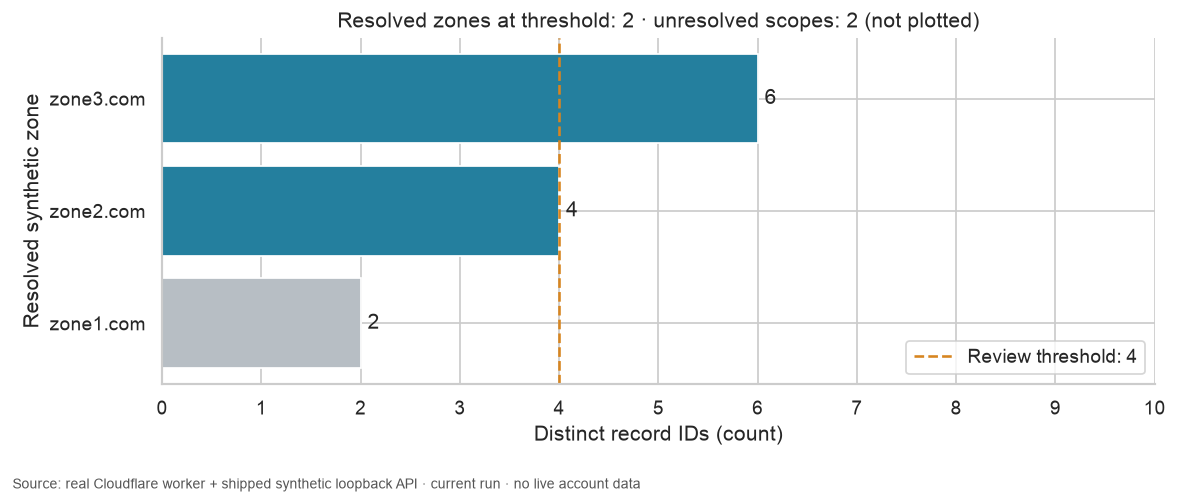

In [14]:
display(counts)
assert len(counts) == len(scope_status)
assert counts.loc[counts.resolved_id.isna(), "record_count"].isna().all()
known = counts[counts.resolved_id.notna()].copy()
assert int(known.record_count.sum()) == len(records)
assert (known.name_count <= known.record_count).all()
flagged = int(known.record_count.ge(REVIEW_MIN_RECORDS).sum())
unresolved = int(counts.resolved_id.isna().sum())
prose(
    f"At **{REVIEW_MIN_RECORDS} records**, **{flagged} of {len(known)} resolved zones** enter the count-based queue. "
    f"The **{unresolved} unresolved scopes** still need identification follow-up and have no numeric inventory count."
)
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ordered = known.sort_values("record_count", ascending=False)
bars = ax.barh(
    ordered.zone_name,
    ordered.record_count,
    color=np.where(ordered.record_count.ge(REVIEW_MIN_RECORDS), "#247f9e", "#b7bec4"),
)
ax.bar_label(bars, fmt="%.0f", padding=4)
ax.invert_yaxis()
ax.axvline(
    REVIEW_MIN_RECORDS, color="#d78520", linestyle="--", label=f"Review threshold: {REVIEW_MIN_RECORDS}"
)
ax.set(
    xlabel="Distinct record IDs (count)",
    ylabel="Resolved synthetic zone",
    xlim=(0, max(10, int(known.record_count.max()) + 2)),
    title=f"Resolved zones at threshold: {flagged} · unresolved scopes: {unresolved} (not plotted)",
)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.legend(loc="lower right")
finish(fig)

## Check how much name-only counting would discard

The second view holds the source constant and changes only the counting key. The gap between the two bars is the number of distinct record identities lost if this fixture were reduced to one row per DNS name. It is unrelated to the review threshold.

In [15]:
%%sql identity_counts <<
SELECT zone_name,record_count,name_count,record_count-name_count AS identities_lost_by_name_only
FROM scope_counts WHERE resolved_id IS NOT NULL ORDER BY scope_order;

,zone_name,record_count,name_count,identities_lost_by_name_only
0,zone1.com,2,1,1
1,zone2.com,4,2,2
2,zone3.com,6,3,3


Name-only counting would retain **6 names** instead of **12 record identities**, a reduction of **6 identities** in this fixture. Keep the record ID and parent zone when the question concerns inventory size; use names when the question concerns name coverage.

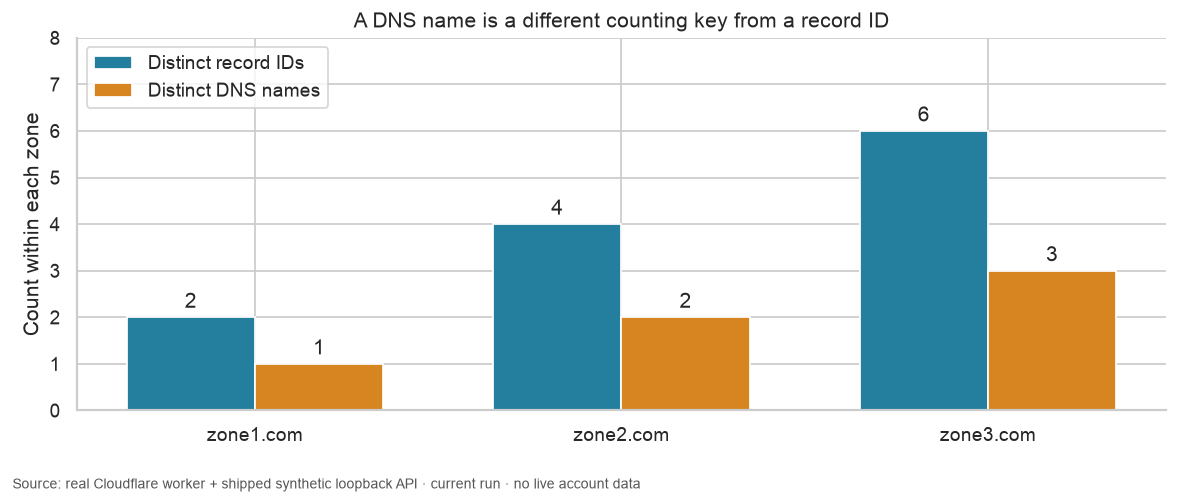

In [16]:
display(identity_counts)
lost = int(identity_counts.identities_lost_by_name_only.sum())
prose(
    f"Name-only counting would retain **{int(identity_counts.name_count.sum())} names** instead of **{int(identity_counts.record_count.sum())} record identities**, "
    f"a reduction of **{lost} identities** in this fixture. Keep the record ID and parent zone when the question concerns inventory size; use names when the question concerns name coverage."
)
fig, ax = plt.subplots(figsize=(9.5, 4.2))
x = np.arange(len(identity_counts))
width = 0.35
b1 = ax.bar(x - width / 2, identity_counts.record_count, width, color="#247f9e", label="Distinct record IDs")
b2 = ax.bar(x + width / 2, identity_counts.name_count, width, color="#d78520", label="Distinct DNS names")
ax.bar_label(b1, padding=3, fmt="%.0f")
ax.bar_label(b2, padding=3, fmt="%.0f")
ax.set(
    xticks=x,
    xticklabels=identity_counts.zone_name,
    ylabel="Count within each zone",
    ylim=(0, float(identity_counts.record_count.max()) + 2),
    title="A DNS name is a different counting key from a record ID",
)
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.legend(loc="upper left")
finish(fig)

## One change to test

Change only **`REVIEW_MIN_RECORDS` from `4` to `6`** and execute a separate copy using the [README](README.md). Compare the review reason table and first chart. The inventory fingerprint, request-page audit, unresolved count and second chart should remain unchanged.

Restore **4** afterward. This experiment validates counting and coverage for the shipped fixture. A real audit also needs an explicit account/zone scope, suitable read permissions and handling for upstream errors. A successful lookup does not prove account-wide completeness, and a missing lookup does not establish a zero-record zone. The notebook's local HTTP server is shut down after worker detachment.

In [17]:
con.execute("DETACH cf")
con.close()
server.shutdown()
server.server_close()
server_thread.join(timeout=5)

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and fixture provenance](README.md)